# Chapter 39: Hard choices and temperature

Checks [chapter 39](../../book/39-hard-choices-and-temperature.md). The models are the ones the theorems are about:
the softmax of a list of real scores divided by a temperature (`cold_softmax_picks_the_top_score`, `colder_sampler_picks_better_on_average`),
a hard step with a gentle stand-in (`straight_through_forward_is_the_hard_step`, `straight_through_backward_has_the_stand_in_slope`, `hard_step_sends_no_gradient_back`),
unit-vector patterns with the modern Hopfield update against the ideal denoiser (`hopfield_recall_equals_ideal_denoiser`), and a decoder
of known slope limit with a codebook (`snapping_moves_output_at_most_slope_times_distance`, `nearest_entry_is_the_gentlest_snap`). Everything is NumPy in float64,
seeded. These are measurements, not proofs: the proofs are in `HardChoices.lean` and `Temperature.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 39


def apply_softmax(scores):
    shifted = scores - scores.max(axis=-1, keepdims=True)
    exponentials = np.exp(shifted)
    return exponentials / exponentials.sum(axis=-1, keepdims=True)


def get_gap(scores):
    """How far the best score leads the runner-up."""
    ordered = np.sort(scores, axis=-1)
    return ordered[..., -1] - ordered[..., -2]


def get_average_score(scores, inverse_temperature):
    return (apply_softmax(inverse_temperature * scores) * scores).sum(axis=-1)

## The worked example: scores 3, 1, 0

Prediction: shares 0.844, 0.114, 0.042 at temperature 1 with average about 2.65 and a miss of 0.156; shares 0.980, 0.018,
0.002 at temperature 0.5 with average about 2.96 and a miss of 0.020. The bound `2 exp(-2/T)` is 0.27 and 0.037.
A different number in the third decimal would count against the chapter's arithmetic.

In [2]:
example_scores = np.array([3.0, 1.0, 0.0])
for temperature in (1.0, 0.5):
    shares = apply_softmax(example_scores / temperature)
    average = float(shares @ example_scores)
    miss = 1.0 - shares[0]
    bound = 2 * np.exp(-2.0 / temperature)
    print(f"temperature {temperature}: shares {np.round(shares, 3)}, average {average:.3f}, miss {miss:.3f}, bound {bound:.3f}")
shares_one = apply_softmax(example_scores)
shares_half = apply_softmax(example_scores / 0.5)
report("hand example: shares at temperature 1 are 0.844, 0.114, 0.042",
       np.allclose(shares_one, [0.844, 0.114, 0.042], atol=5e-4), f"{np.round(shares_one, 4)}")
report("hand example: shares at temperature 0.5 are 0.980, 0.018, 0.002",
       np.allclose(shares_half, [0.980, 0.018, 0.002], atol=5e-4), f"{np.round(shares_half, 4)}")
report("hand example: averages are 2.65 and 2.96",
       abs(shares_one @ example_scores - 2.65) < 5e-3 and abs(shares_half @ example_scores - 2.96) < 5e-3,
       f"{shares_one @ example_scores:.4f}, {shares_half @ example_scores:.4f}")

temperature 1.0: shares [0.844 0.114 0.042], average 2.646, miss 0.156, bound 0.271
temperature 0.5: shares [0.98  0.018 0.002], average 2.957, miss 0.020, bound 0.037
[PASS] hand example: shares at temperature 1 are 0.844, 0.114, 0.042  ([0.8438 0.1142 0.042 ])
[PASS] hand example: shares at temperature 0.5 are 0.980, 0.018, 0.002  ([0.9796 0.0179 0.0024])
[PASS] hand example: averages are 2.65 and 2.96  (2.6456, 2.9568)


True

## Claim 1: a cold softmax puts nearly all its share on the top score (`cold_softmax_picks_the_top_score`)

Prediction: for every list of scores and every temperature, the miss `1 - share(top)` is at most
`(number of choices - 1) * exp(-gap / temperature)` when `gap` is any value the top score leads every other by. Test with
2000 random lists, with 2 to 12 scores drawn from a normal distribution, and 12 temperatures from 0.05 to 5, using the exact
gap (best minus runner-up, the tightest allowed) and also half of it. Counting against the claim: a single
list where the miss exceeds the bound. The control breaks the hypothesis: use a gap *larger* than the true one (twice it);
the theorem then does not apply, and the bound should fail for some lists. The size of the failure is the largest miss minus bound.

In [3]:
generator = np.random.default_rng(SEED)
TEMPERATURES = np.geomspace(0.05, 5.0, 12)
worst_slack = np.inf          # smallest (bound - miss) over exact-gap cases: must be >= 0
worst_slack_half = np.inf
control_failures = 0
control_worst = 0.0
tested = 0
tightest_case = None
for _ in range(2000):
    choice_count = int(generator.integers(2, 13))
    scores = generator.standard_normal(choice_count) * generator.uniform(0.5, 3.0)
    top_index = scores.argmax()
    gap = get_gap(scores)
    for temperature in TEMPERATURES:
        miss = 1.0 - apply_softmax(scores / temperature)[top_index]
        bound = (choice_count - 1) * np.exp(-gap / temperature)
        bound_half = (choice_count - 1) * np.exp(-0.5 * gap / temperature)
        bound_wrong = (choice_count - 1) * np.exp(-2.0 * gap / temperature)
        if bound - miss < worst_slack:
            tightest_case = (choice_count, float(gap), float(temperature))
        worst_slack = min(worst_slack, bound - miss)
        worst_slack_half = min(worst_slack_half, bound_half - miss)
        if miss > bound_wrong + 1e-15:
            control_failures += 1
            control_worst = max(control_worst, miss - bound_wrong)
        tested += 1
print(f"smallest margin: {tightest_case[0]} choices, gap {tightest_case[1]:.3f}, temperature {tightest_case[2]:.3f}, gap over temperature {tightest_case[1] / tightest_case[2]:.1f}")
report("miss <= (count - 1) exp(-gap / T) with the exact gap", worst_slack >= -1e-12,
       f"{tested} cases, smallest bound minus miss {worst_slack:.2e}")
report("the same holds with half the gap", worst_slack_half >= -1e-12, f"smallest bound minus miss {worst_slack_half:.2e}")
report("control: with twice the true gap the bound fails somewhere", control_failures > 0,
       f"{control_failures} of {tested} cases fail, worst miss minus bound {control_worst:.3f}")

smallest margin: 2 choices, gap 5.032, temperature 0.267, gap over temperature 18.9


[PASS] miss <= (count - 1) exp(-gap / T) with the exact gap  (24000 cases, smallest bound minus miss -1.11e-16)
[PASS] the same holds with half the gap  (smallest bound minus miss 6.92e-40)
[PASS] control: with twice the true gap the bound fails somewhere  (10986 of 24000 cases fail, worst miss minus bound 0.267)


True

## Claim 2: a colder sampler never has a lower average score (`colder_sampler_picks_better_on_average`)

Prediction: for every list of scores, the average score of the softmax of `inverse_temperature * scores` is non-decreasing in
`inverse_temperature`. Test with 2000 random lists of 2 to 12 scores on 200 inverse temperatures from 0 to 20: every successive
difference must be at least minus rounding error (1e-12). Counting against the claim: a drop larger than that.
The control is a different quantity: the share of the runner-up. The theorem says nothing about it, and it should
rise and then fall as the sampler gets colder, so it should fail to be monotone in a clear fraction of lists (more than 5 percent).

In [4]:
generator = np.random.default_rng(SEED + 1)
INVERSE_TEMPERATURES = np.linspace(0.0, 20.0, 200)
lowest_step = np.inf
runner_up_not_monotone = 0
LIST_COUNT = 2000
for _ in range(LIST_COUNT):
    choice_count = int(generator.integers(2, 13))
    scores = generator.standard_normal(choice_count) * generator.uniform(0.5, 3.0)
    averages = np.array([get_average_score(scores, inverse) for inverse in INVERSE_TEMPERATURES])
    lowest_step = min(lowest_step, np.diff(averages).min())
    runner_up_index = np.argsort(scores)[-2]
    runner_up_shares = np.array([apply_softmax(inverse * scores)[runner_up_index] for inverse in INVERSE_TEMPERATURES])
    steps = np.diff(runner_up_shares)
    runner_up_not_monotone += bool(steps.max() > 1e-9 and steps.min() < -1e-9)
report("the average score never falls as the sampler gets colder", lowest_step >= -1e-12,
       f"{LIST_COUNT} lists, smallest step {lowest_step:.2e}")
report("control: the runner-up share is not monotone in many lists", runner_up_not_monotone > 0.05 * LIST_COUNT,
       f"{runner_up_not_monotone} of {LIST_COUNT} lists rise and then fall")

[PASS] the average score never falls as the sampler gets colder  (2000 lists, smallest step -1.78e-15)
[PASS] control: the runner-up share is not monotone in many lists  (1667 of 2000 lists rise and then fall)


True

## Claim 3: the straight-through trick (`straight_through_forward_is_the_hard_step`, `straight_through_backward_has_the_stand_in_slope`, `hard_step_sends_no_gradient_back`)

Take the hard step `hard(input) = 1 if input >= 0.2 else 0` (value 1 at 0.3) and the stand-in `soft(input) = 2 * input`,
anchor 0.3. Prediction: `through(0.3) = 1` exactly, a central difference of `through` at 0.3 is 2 up to rounding, a central
difference of `hard` at 0.3 is 0 (a step has slope zero away from its jump), and the slope of `through` equals the slope of `soft`
at 20 further points. Counting against the claim: the value not 1, or a slope not 2. The control: at the jump
itself the hard step's difference quotient is huge, so the slope-zero claim must fail there.

Note: `through(0.3) = 1` and the slope 2 of `through` hold by construction (the algebra cancels the stand-in), so those lines are printed as `[by construction, cannot fail]` and are not counted as evidence. Only the step's slope of zero away from its jump, and the control at the jump, can fail.

In [5]:
def hard(input_value):
    return np.where(np.asarray(input_value) >= 0.2, 1.0, 0.0)


def soft(input_value):
    return 2.0 * np.asarray(input_value)


def through(input_value, anchor=0.3):
    return hard(anchor) - soft(anchor) + soft(input_value)


STEP = 1e-5
value_at_anchor = float(through(0.3))
through_slope = (through(0.3 + STEP) - through(0.3 - STEP)) / (2 * STEP)
hard_slope = (hard(0.3 + STEP) - hard(0.3 - STEP)) / (2 * STEP)
print(f"[by construction, cannot fail] through(0.3) = {value_at_anchor:.12f}")
print(f"[by construction, cannot fail] slope of through at 0.3 = {float(through_slope):.8f}")
report("the hard step has slope zero at 0.3", abs(hard_slope) < 1e-12, f"slope {float(hard_slope):.1e}")
others = np.linspace(0.25, 3.0, 20)
slopes_away = (through(others + STEP) - through(others - STEP)) / (2 * STEP)
print(f"[by construction, cannot fail] largest deviation of the slope from 2 at 20 other points {np.abs(slopes_away - 2.0).max():.1e}")
jump_slope = float((hard(0.2 + STEP) - hard(0.2 - STEP)) / (2 * STEP))
report("control: at the jump itself the hard step has no zero slope", abs(jump_slope) > 1e3, f"difference quotient {jump_slope:.0f}")

[by construction, cannot fail] through(0.3) = 1.000000000000
[by construction, cannot fail] slope of through at 0.3 = 2.00000000
[PASS] the hard step has slope zero at 0.3  (slope 0.0e+00)
[by construction, cannot fail] largest deviation of the slope from 2 at 20 other points 1.3e-11
[PASS] control: at the jump itself the hard step has no zero slope  (difference quotient 50000)


True

## Claim 4: modern Hopfield recall is the ideal denoiser (`hopfield_recall_equals_ideal_denoiser`)

The ideal denoiser at noise level `sigma` is the average of the patterns weighted by the softmax of `-|state - pattern|^2 / (2 sigma^2)`.
Prediction: for unit-length patterns and a unit-length state, the Hopfield update (softmax of overlap over `T`, averaged over patterns)
equals the ideal denoiser at `sigma = sqrt(T)`, to rounding error. Test with 500 random draws in dimension 8, 3 to 10 patterns,
and `T` between 0.05 and 2. Counting against the claim: a difference above 1e-12. The control breaks the hypothesis: patterns of
unequal length (lengths drawn from 0.5 to 1.5). The two then use different shares, and the difference should be clearly non-zero.
I first expected a state of length 1.5 to break it too; it does not, because the state's length only shifts every squared distance by
the same amount, so I check that separately and report it. I also measure the distance from
the recalled vector to the span of the patterns, to check the "never leaves the region they span" sentence (it is a combination of the
patterns, so the distance should be zero up to rounding).

In [6]:
def update_hopfield(state, patterns, temperature):
    shares = apply_softmax(patterns @ state / temperature)
    return shares @ patterns


def denoise_ideally(noise_level, patterns, state):
    squared = ((patterns - state) ** 2).sum(axis=1)
    shares = apply_softmax(-squared / (2 * noise_level ** 2))
    return shares @ patterns


generator = np.random.default_rng(SEED + 2)
DIMENSION = 8
largest_difference = 0.0
largest_control = 0.0
largest_long_state = 0.0
largest_outside_span = 0.0
for _ in range(500):
    pattern_count = int(generator.integers(3, 11))
    patterns = generator.standard_normal((pattern_count, DIMENSION))
    patterns /= np.linalg.norm(patterns, axis=1, keepdims=True)
    state = generator.standard_normal(DIMENSION)
    state /= np.linalg.norm(state)
    temperature = generator.uniform(0.05, 2.0)
    recalled = update_hopfield(state, patterns, temperature)
    denoised = denoise_ideally(np.sqrt(temperature), patterns, state)
    largest_difference = max(largest_difference, np.abs(recalled - denoised).max())
    long_state = 1.5 * state
    long_difference = np.abs(update_hopfield(long_state, patterns, temperature)
                             - denoise_ideally(np.sqrt(temperature), patterns, long_state)).max()
    largest_long_state = max(largest_long_state, long_difference)
    uneven = patterns * generator.uniform(0.5, 1.5, size=(pattern_count, 1))
    control = np.abs(update_hopfield(state, uneven, temperature)
                     - denoise_ideally(np.sqrt(temperature), uneven, state)).max()
    largest_control = max(largest_control, control)
    projection = patterns.T @ np.linalg.lstsq(patterns.T, recalled, rcond=None)[0]
    largest_outside_span = max(largest_outside_span, np.linalg.norm(recalled - projection))
report("Hopfield update equals the ideal denoiser for unit patterns and a unit state", largest_difference < 1e-12,
       f"largest difference {largest_difference:.1e} over 500 draws")
report("control: patterns of unequal length break the equality", largest_control > 1e-3,
       f"largest difference {largest_control:.3f}")
print(f"extra: a state of length 1.5 gives a largest difference of {largest_long_state:.1e}")
report("the recalled vector lies in the span of the patterns", largest_outside_span < 1e-10,
       f"largest distance to the span {largest_outside_span:.1e}")

[PASS] Hopfield update equals the ideal denoiser for unit patterns and a unit state  (largest difference 1.0e-15 over 500 draws)
[PASS] control: patterns of unequal length break the equality  (largest difference 0.950)
extra: a state of length 1.5 gives a largest difference of 7.5e-16
[PASS] the recalled vector lies in the span of the patterns  (largest distance to the span 3.6e-15)


True

## Claim 5: snapping to a codebook entry (`snapping_moves_output_at_most_slope_times_distance`, `nearest_entry_is_the_gentlest_snap`)

The decoder is two layers, `tanh(tanh(code @ matrix_one.T) @ matrix_two.T)`. Tanh has slope at most 1, so the slope limit is the
product of the two spectral norms. Prediction: for 300 random codes and a codebook of 20 entries, the output change from
snapping to any entry is at most `slope_limit` times the distance to it, and for the nearest entry the output change is at most
`slope_limit` times the distance to every entry. Counting against the claim: one violation. This claim has no control: the bound is the definition of a slope limit applied to two points, so there is no natural way to break the hypothesis other than stating a false slope limit, which fails trivially and shows nothing.

In [7]:
generator = np.random.default_rng(SEED + 3)
matrix_one = generator.standard_normal((16, 6)) / 2.0
matrix_two = generator.standard_normal((5, 16)) / 2.0
SLOPE_LIMIT = np.linalg.norm(matrix_one, 2) * np.linalg.norm(matrix_two, 2)


def decode(codes):
    return np.tanh(np.tanh(codes @ matrix_one.T) @ matrix_two.T)


codebook = generator.standard_normal((20, 6))
worst_ratio = 0.0
nearest_violations = 0
any_entry_violations = 0
pair_count = 0
for _ in range(300):
    code_vector = generator.standard_normal(6) * 1.5
    distances = np.linalg.norm(codebook - code_vector, axis=1)
    changes = np.linalg.norm(decode(codebook) - decode(code_vector), axis=1)
    nearest = distances.argmin()
    any_entry_violations += int((changes > SLOPE_LIMIT * distances + 1e-12).sum())
    nearest_violations += int((changes[nearest] > SLOPE_LIMIT * distances + 1e-12).sum())
    worst_ratio = max(worst_ratio, (changes / distances).max())
    pair_count += len(distances)
report("snapping to any entry moves the output by at most slope times distance", any_entry_violations == 0,
       f"{pair_count} pairs, largest change per distance {worst_ratio:.3f} against slope limit {SLOPE_LIMIT:.3f}")
report("snapping to the nearest entry is within slope times the distance to every entry", nearest_violations == 0,
       f"{nearest_violations} violations")


[PASS] snapping to any entry moves the output by at most slope times distance  (6000 pairs, largest change per distance 1.790 against slope limit 6.897)
[PASS] snapping to the nearest entry is within slope times the distance to every entry  (0 violations)


True

## The figure: the dial and the bound

Left: the softmax of the scores 3, 1, 0 at three temperatures, as bars. Right: the true miss of the top score against the
temperature, and the bound of `cold_softmax_picks_the_top_score` (gap 2, two other choices) on the same axes. Everything drawn is computed here.

wrote book/figures/39-dial-and-bound.png


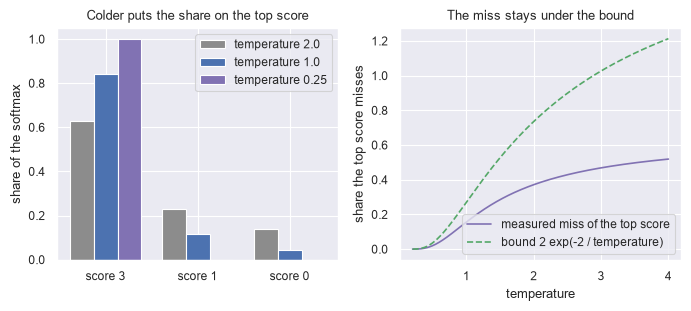

In [8]:
figure, (bars_axis, miss_axis) = plt.subplots(1, 2, figsize=(7.0, 3.2))
bar_temperatures = (2.0, 1.0, 0.25)
bar_colours = (BEFORE, NEAREST, MODEL)
width = 0.26
for offset, (temperature, colour) in enumerate(zip(bar_temperatures, bar_colours)):
    shares = apply_softmax(example_scores / temperature)
    bars_axis.bar(np.arange(3) + (offset - 1) * width, shares, width, color=colour, label=f"temperature {temperature}")
bars_axis.set_xticks(range(3), [f"score {int(score)}" for score in example_scores])
bars_axis.set_ylabel("share of the softmax")
bars_axis.set_title("Colder puts the share on the top score")
bars_axis.legend()

temperature_grid = np.linspace(0.2, 4.0, 300)
measured_miss = np.array([1.0 - apply_softmax(example_scores / temperature)[0] for temperature in temperature_grid])
proved_bound = 2 * np.exp(-2.0 / temperature_grid)
assert np.all(measured_miss <= proved_bound + 1e-12)
miss_axis.plot(temperature_grid, measured_miss, color=MODEL, label="measured miss of the top score")
miss_axis.plot(temperature_grid, proved_bound, color=BOUND, linestyle="--", label="bound 2 exp(-2 / temperature)")
miss_axis.set_xlabel("temperature")
miss_axis.set_ylabel("share the top score misses")
miss_axis.set_title("The miss stays under the bound")
miss_axis.legend()
figure.tight_layout()
save_figure(figure, "39-dial-and-bound")
plt.show()

## A second figure: the average score against the inverse temperature

Five random lists of scores, the average score of a sample against the inverse temperature (one over the temperature),
from `colder_sampler_picks_better_on_average`. Beside it is the control from claim 2: the share of the runner-up for one list, which
rises and then falls. The first curve is the quantity the theorem is about, the second is one it is silent on.

wrote book/figures/39-average-against-inverse-temperature.png


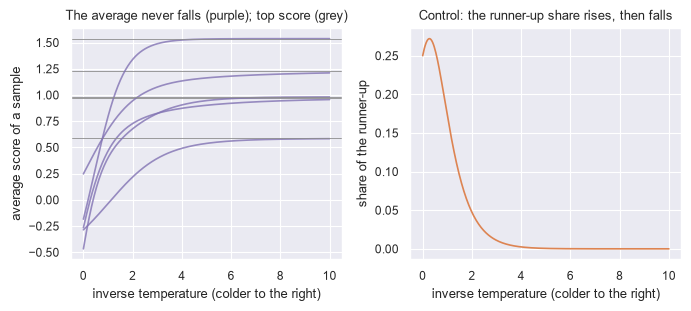

In [9]:
generator = np.random.default_rng(SEED + 4)
figure, (average_axis, runner_axis) = plt.subplots(1, 2, figsize=(7.0, 3.2))
inverse_grid = np.linspace(0.0, 10.0, 300)
for _ in range(5):
    scores = generator.standard_normal(6)
    averages = np.array([get_average_score(scores, inverse) for inverse in inverse_grid])
    assert np.diff(averages).min() >= -1e-12
    average_axis.plot(inverse_grid, averages, color=MODEL, alpha=0.8)
    average_axis.axhline(scores.max(), color=BEFORE, linewidth=0.6)
average_axis.set_xlabel("inverse temperature (colder to the right)")
average_axis.set_ylabel("average score of a sample")
average_axis.set_title("The average never falls (purple); top score (grey)")

scores = np.array([3.0, 1.5, 0.0, -1.0])
runner_up_shares = np.array([apply_softmax(inverse * scores)[1] for inverse in inverse_grid])
assert np.diff(runner_up_shares).max() > 0 and np.diff(runner_up_shares).min() < 0
runner_axis.plot(inverse_grid, runner_up_shares, color=VERTICAL)
runner_axis.set_xlabel("inverse temperature (colder to the right)")
runner_axis.set_ylabel("share of the runner-up")
runner_axis.set_title("Control: the runner-up share rises, then falls")
figure.tight_layout()
save_figure(figure, "39-average-against-inverse-temperature")
plt.show()